# Импорт и загрузка данных

In [63]:
# ==========================================
# ДИПЛОМНАЯ РАБОТА: A/B-тест SkyLenta
# Шаг 1: Импорт библиотек и загрузка данных
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Настройка визуализации
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Путь к файлу с данными (относительный, так как файл лежит в той же папке)
file_path = 'Новый диплом датасет update.xlsx'

# Загружаем все три листа
file = pd.ExcelFile(file_path)
print(f"Листы в файле: {file.sheet_names}")

# Читаем каждый лист в отдельный DataFrame
data = pd.read_excel(file, sheet_name='Данные')       # платежи
clients = pd.read_excel(file, sheet_name='Clients')   # клиенты и группы
regions = pd.read_excel(file, sheet_name='Region_dict')  # словарь городов

# Изучаем таблицы
print("\n" + "="*60)
print("ТАБЛИЦА 'Данные' (платежи)")
print("="*60)
print(f"Размер: {data.shape}")
display(data.head())
print("\nТипы данных:")
print(data.dtypes)
print(f"\nПропуски:\n{data.isnull().sum()}")

print("\n" + "="*60)
print("ТАБЛИЦА 'Clients' (клиенты)")
print("="*60)
print(f"Размер: {clients.shape}")
display(clients.head())
print("\nТипы данных:")
print(clients.dtypes)
print(f"\nПропуски:\n{clients.isnull().sum()}")

print("\n" + "="*60)
print("ТАБЛИЦА 'Region_dict' (регионы)")
print("="*60)
print(f"Размер: {regions.shape}")
display(regions.head())
print("\nТипы данных:")
print(regions.dtypes)
print(f"\nПропуски:\n{regions.isnull().sum()}")

Листы в файле: ['Данные', 'Clients', 'Region_dict']

ТАБЛИЦА 'Данные' (платежи)
Размер: (37989, 4)


,id_order,id_client,amt_payment,dtime_pay
0,100238,194569.0,5373.0,2022-07-17 21:48:15.896
1,100242,191056.0,4151.0,2022-07-07 03:09:39.699
2,100249,200049.0,5688.0,2022-07-29 13:25:59.976
3,100258,206161.0,4330.0,2022-08-15 22:55:02.538
4,100267,190945.0,5488.0,2022-07-05 19:46:47.174



Типы данных:
id_order                int64
id_client             float64
amt_payment           float64
dtime_pay      datetime64[us]
dtype: object

Пропуски:
id_order          0
id_client       588
amt_payment    2144
dtime_pay      2429
dtype: int64

ТАБЛИЦА 'Clients' (клиенты)
Размер: (55605, 4)


,id_client,dtime_ad,nflag_test,id_trading_point
0,180844,2022-06-08 18:38:41.414,0,212
1,193942,NaT,0,13
2,226069,2022-07-11 16:28:38.511,1,54
3,183981,2022-06-16 12:23:59.289,1,991
4,322530,2022-07-08 08:56:08.714,0,1015



Типы данных:
id_client                    int64
dtime_ad            datetime64[us]
nflag_test                   int64
id_trading_point             int64
dtype: object

Пропуски:
id_client             0
dtime_ad            249
nflag_test            0
id_trading_point      0
dtype: int64

ТАБЛИЦА 'Region_dict' (регионы)
Размер: (66, 2)


,id_trading_point,city
0,1,Петрозаводск
1,2,Дмитров
2,4,Чехов
3,7,Ростов Великий
4,11,Владимир



Типы данных:
id_trading_point    int64
city                  str
dtype: object

Пропуски:
id_trading_point    0
city                0
dtype: int64


# Удаление пропусков + группировка ТТ по городам

Строк с пропусками в 'Данные': 2429
Строк с пропусками в 'Clients': 249
Строк с пропусками в 'Region_dict': 0

Размеры после удаления пропусков:
  Данные: (35560, 4)
  Clients: (55356, 4)
  Region_dict: (66, 2)

Пропуски после очистки:
id_order       0
id_client      0
amt_payment    0
dtime_pay      0
dtype: int64
id_client           0
dtime_ad            0
nflag_test          0
id_trading_point    0
dtype: int64

Количество торговых точек по городам:
city
Москва              11
Санкт-Петербург     11
Казань               6
Новосибирск          6
Красноярск           5
Самара               4
Краснодар            4
Саратов              2
Сочи                 2
Мурманск             2
Волгоград            1
Дмитров              1
Великий Новгород     1
Владимир             1
Нижний Новгород      1
Ростов-на-Дону       1
Ростов Великий       1
Петрозаводск         1
Сахалинск            1
Тольятти             1
Тюмень               1
Чехов                1
Ярославль            1
Name: id_

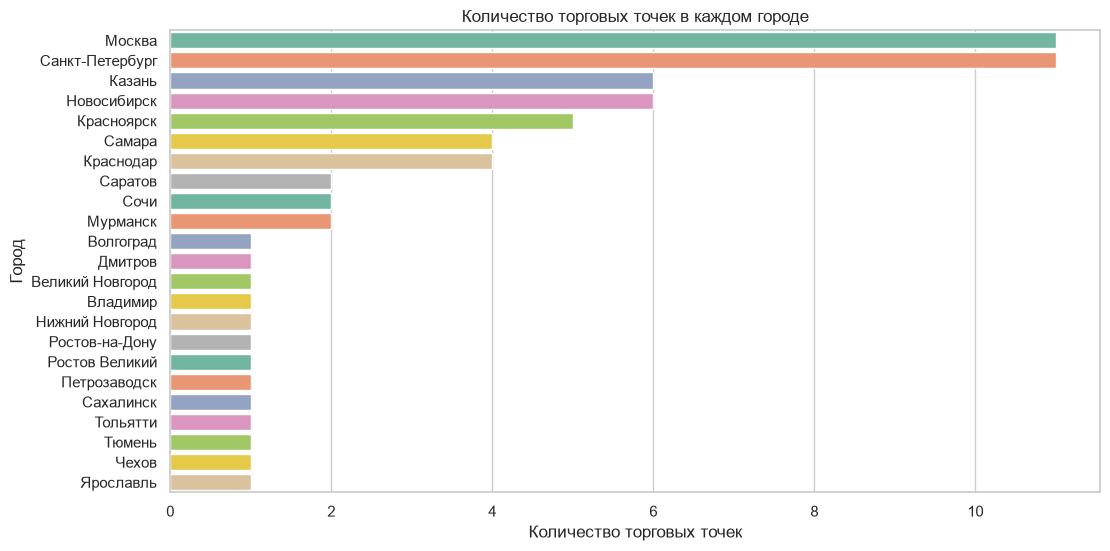

In [64]:
# ==========================================
# Шаг 1 (продолжение): обработка пропусков и анализ торговых точек
# ==========================================

# Считаем строки с пропусками в каждой таблице
print(f"Строк с пропусками в 'Данные': {data.isnull().any(axis=1).sum()}")
print(f"Строк с пропусками в 'Clients': {clients.isnull().any(axis=1).sum()}")
print(f"Строк с пропусками в 'Region_dict': {regions.isnull().any(axis=1).sum()}")

# Удаляем строки с нуллевыми значениями
# Обоснование: 
# - в 'Данные' без id_client нельзя привязать платёж к клиенту, без amt_payment — 
#   посчитать сумму, без dtime_pay — определить период покупки;
# - в 'Clients' без dtime_ad неизвестен момент показа рекламы;
# - доли пропусков малы (0.45%–6.4%), поэтому удаление не исказит результаты.
data = data.dropna()
clients = clients.dropna()
regions = regions.dropna()

# Приводим id_client в платежах к int (после удаления NaN это возможно)
data['id_client'] = data['id_client'].astype(int)

print(f"\nРазмеры после удаления пропусков:")
print(f"  Данные: {data.shape}")
print(f"  Clients: {clients.shape}")
print(f"  Region_dict: {regions.shape}")
print(f"\nПропуски после очистки:\n{data.isnull().sum()}\n{clients.isnull().sum()}")

# ==========================================
# Количество торговых точек в каждом городе
# ==========================================
tp_by_city = regions.groupby('city')['id_trading_point'].nunique().sort_values(ascending=False)
print(f"\nКоличество торговых точек по городам:\n{tp_by_city}")

# Визуализация столбчатой диаграммой
plt.figure(figsize=(12, 6))
sns.barplot(x=tp_by_city.values, y=tp_by_city.index, hue=tp_by_city.index, palette='Set2', legend=False)
plt.title('Количество торговых точек в каждом городе')
plt.xlabel('Количество торговых точек')
plt.ylabel('Город')
plt.show()

## Обработка пропусков и анализ торговых точек

**Удаление пропусков:**
- «Данные»: удалено **2429 строк** (без `id_client` нельзя привязать платёж, без `amt_payment` — посчитать сумму, без `dtime_pay` — определить период)
- «Clients»: удалено **249 строк** (без `dtime_ad` неизвестен момент показа рекламы)
- «Region_dict»: пропусков не было

Доли пропусков малы (0.45%–6.4%), поэтому удаление не искажает результаты. Альтернатива (замена на 0) исказила бы расчёт сумм и среднего чека, поэтому выбрано удаление.

**Итоговые размеры:** Данные — 35560, Clients — 55356, Region_dict — 66.

**Торговые точки по городам:** всего **66 ТТ в 23 городах**. Лидеры — Москва и Санкт-Петербург (по 11 ТТ), далее Казань и Новосибирск (по 6), Красноярск (5). Большинство малых городов представлены одной торговой точкой.

# Объединение таблиц

In [65]:
# ==========================================
# Шаг 2: Объединение таблиц
# ==========================================

# 1. Агрегация платежей: сумма платежей на каждого клиента
payments_by_client = data.groupby('id_client', as_index=False)['amt_payment'].sum()
payments_by_client.columns = ['id_client', 'total_payment']
print(f"Агрегированная таблица платежей: {payments_by_client.shape}")
display(payments_by_client.head())

# 2. Соединяем с клиентской таблицей (left join — все клиенты должны остаться)
df = clients.merge(payments_by_client, on='id_client', how='left')
print(f"\nРазмер после соединения: {df.shape}")

# Проверка: все ли клиенты из клиентской таблицы остались
assert df.shape[0] == clients.shape[0], "❌ Не все клиенты остались!"
print(f"✅ Все {clients.shape[0]} клиентов остались после соединения")

# 3. Заполняем нулями суммы покупок тех клиентов, которые их не совершали
df['total_payment'] = df['total_payment'].fillna(0)
print(f"\nКлиентов без покупок (чек = 0): {(df['total_payment'] == 0).sum()}")

# 4. Подтягиваем город к каждой торговой точке через словарь регионов
df = df.merge(regions, on='id_trading_point', how='left')
print(f"\nРазмер после подтягивания города: {df.shape}")
print(f"Пропусков в city после join: {df['city'].isnull().sum()}")

# 5. Создаём флаг платежа (0 или 1)
df['flag_payment'] = (df['total_payment'] > 0).astype(int)
print(f"\nРаспределение флага платежа:")
print(df['flag_payment'].value_counts())
print(f"\nОбщая конверсия в платёж: {df['flag_payment'].mean()*100:.2f}%")

display(df.head())

Агрегированная таблица платежей: (28383, 2)


,id_client,total_payment
0,178561,3052.0
1,178562,2439.0
2,178563,768.0
3,178565,958.0
4,178566,5474.0



Размер после соединения: (55356, 5)
✅ Все 55356 клиентов остались после соединения

Клиентов без покупок (чек = 0): 26973

Размер после подтягивания города: (55356, 6)
Пропусков в city после join: 0

Распределение флага платежа:
flag_payment
1    28383
0    26973
Name: count, dtype: int64

Общая конверсия в платёж: 51.27%


,id_client,dtime_ad,nflag_test,id_trading_point,total_payment,city,flag_payment
0,180844,2022-06-08 18:38:41.414,0,212,5349.0,Красноярск,1
1,226069,2022-07-11 16:28:38.511,1,54,0.0,Мурманск,0
2,183981,2022-06-16 12:23:59.289,1,991,6322.0,Казань,1
3,322530,2022-07-08 08:56:08.714,0,1015,0.0,Краснодар,0
4,254313,2022-06-19 22:18:01.770,1,453,0.0,Санкт-Петербург,0


## Объединение таблиц

1. **Агрегация платежей:** у одного клиента может быть несколько платежей, поэтому платежи просуммированы по каждому клиенту (`groupby + sum`).
2. **Соединение:** агрегированная таблица платежей соединена с клиентской таблицей через `left join` по `id_client`. Проверка (`assert`) подтвердила, что **все 55356 клиентов остались** в итоговой таблице.
3. **Заполнение нулями:** клиентам без покупок проставлен `total_payment = 0`.
4. **Города:** через словарь `Region_dict` к каждой торговой точке подтянут город. Пропусков в `city` нет — все ТТ распознаны.
5. **Флаг платежа:** создано поле `flag_payment` (1 — клиент заплатил, 0 — нет). Общая конверсия в платёж — **51.27%**.

# Функции статистических тестов

In [66]:
# ==========================================
# Шаг 3: Автоматизация статистических вычислений
# ==========================================

from scipy import stats

def test_calc(r1, r2, alpha=0.05):
    """
    Вычисляет t-критерий Стьюдента и p_value для сравнения средних.
    Выводит сообщение о том, существует ли разница между средними.
    
    Аргументы:
        r1 - первая выборка
        r2 - вторая выборка
        alpha - уровень значимости (по умолчанию 5%)
    
    Возвращает:
        t_stat, p_value
    """
    t_stat, p_value = stats.ttest_ind(r1, r2, equal_var=False)
    print(f"  t-статистика: {t_stat:.4f}, p-value: {p_value:.4f}")
    if p_value < alpha:
        print(f"  ✅ p-value ({p_value:.4f}) < alpha ({alpha}) → РАЗНИЦА ЕСТЬ (отвергаем H0)")
    else:
        print(f"  ❌ p-value ({p_value:.4f}) >= alpha ({alpha}) → РАЗНИЦЫ НЕТ (принимаем H0)")
    return t_stat, p_value


def mann_whitney_func(r1, r2, alpha=0.05):
    """
    Рассчитывает критерий Манна-Уитни и p_value для сравнения распределений.
    Выводит сообщение о том, существует ли разница между распределениями.
    
    Аргументы:
        r1 - первая выборка
        r2 - вторая выборка
        alpha - уровень значимости (по умолчанию 5%)
    
    Возвращает:
        u_stat, p_value
    """
    u_stat, p_value = stats.mannwhitneyu(r1, r2, alternative='two-sided')
    print(f"  U-статистика: {u_stat:.4f}, p-value: {p_value:.4f}")
    if p_value < alpha:
        print(f"  ✅ p-value ({p_value:.4f}) < alpha ({alpha}) → РАЗНИЦА ЕСТЬ (отвергаем H0)")
    else:
        print(f"  ❌ p-value ({p_value:.4f}) >= alpha ({alpha}) → РАЗНИЦЫ НЕТ (принимаем H0)")
    return u_stat, p_value

print("✅ Функции test_calc и mann_whitney_func созданы")

✅ Функции test_calc и mann_whitney_func созданы


## Автоматизация статистических вычислений

Созданы две функции для проверки гипотез:

1. **`test_calc(r1, r2, alpha=0.05)`** — двухвыборочный t-критерий Стьюдента (с поправкой Велча, `equal_var=False`) для сравнения **средних значений**. Выводит t-статистику, p-value и текстовое заключение о наличии/отсутствии разницы.

2. **`mann_whitney_func(r1, r2, alpha=0.05)`** — непараметрический критерий **Манна-Уитни** для сравнения **распределений**. Используется как дополнительная проверка, так как не требует предположения о нормальности данных (платежи распределены ненормально).

Обе функции принимают две выборки и уровень значимости alpha (по умолчанию 0.05) и возвращают статистику и p-value.

# Чистка неверно заполненных торговых точек

In [67]:
# ==========================================
# Шаг 4: Чистка неверно заполненных торговых точек
# ==========================================

# Список 1: точки, в которых в тестовой ИЛИ контрольной группе
# не было заплачено ни одного рубля ни одним клиентом
zero_payment_points = []

# Список 2: точки, в которых пустует контрольная ИЛИ тестовая группа
empty_group_points = []

# Цикл по всем торговым точкам
for tp in df['id_trading_point'].unique():
    tp_data = df[df['id_trading_point'] == tp]
    
    # Разделяем на группы внутри точки
    test_data = tp_data[tp_data['nflag_test'] == 1]
    control_data = tp_data[tp_data['nflag_test'] == 0]
    
    # Проверка 1: сумма платежей в тесте или контроле равна 0
    if test_data['total_payment'].sum() == 0 or control_data['total_payment'].sum() == 0:
        zero_payment_points.append(tp)
    
    # Проверка 2: в точке нет ни одного клиента теста или контроля
    if len(test_data) == 0 or len(control_data) == 0:
        empty_group_points.append(tp)

print(f"🔍 Точек, где не заплачено ни рубля в тесте или контроле: {len(zero_payment_points)}")
print(f"   ID точек: {zero_payment_points}")

print(f"\n🔍 Точек, где пустует тестовая или контрольная группа: {len(empty_group_points)}")
print(f"   ID точек: {empty_group_points}")

# Объединяем оба списка (убираем возможные повторы через set)
bad_points = list(set(zero_payment_points + empty_group_points))
print(f"\n⚠️ Всего неверно заполненных точек к удалению: {len(bad_points)}")

🔍 Точек, где не заплачено ни рубля в тесте или контроле: 15
   ID точек: [np.int64(1015), np.int64(866), np.int64(1099), np.int64(739), np.int64(46), np.int64(228), np.int64(26), np.int64(603), np.int64(810), np.int64(800), np.int64(7), np.int64(23), np.int64(4), np.int64(1), np.int64(13)]

🔍 Точек, где пустует тестовая или контрольная группа: 8
   ID точек: [np.int64(1015), np.int64(866), np.int64(1099), np.int64(739), np.int64(228), np.int64(603), np.int64(810), np.int64(800)]

⚠️ Всего неверно заполненных точек к удалению: 15


## Чистка неверно заполненных торговых точек

С помощью циклов по всем торговым точкам созданы два списка «проблемных» точек:

**1. Точки с нулевыми платежами (15 точек):**
торговые точки, в которых в тестовой или контрольной группе не было заплачено ни одного рубля ни одним клиентом. В таких точках невозможно корректно сравнить средние платежи между группами.
ID точек: 1015, 866, 1099, 739, 46, 228, 26, 603, 810, 800, 7, 23, 4, 1, 13.

**2. Точки с пустой группой (8 точек):**
торговые точки, в которых полностью отсутствует либо контрольная, либо тестовая группа. Сравнение в таких точках невозможно в принципе.
ID точек: 1015, 866, 1099, 739, 228, 603, 810, 800.

**Объединённый список:** после объединения обоих списков (с удалением повторов через `set`) получено **15 торговых точек**, подлежащих исключению из анализа. Обрати внимание: все 8 точек с пустой группой одновременно входят в список точек с нулевыми платежами (если группа отсутствует, то и сумма её платежей равна 0).

**Обоснование исключения:** если сумма платежей или количество наблюдений в одной из групп равно 0, то мы не сможем сравнить платежи в тестовой и контрольной группах, или такое сравнение будет неверным. Эти 15 точек будут отброшены на следующем шаге при расчёте общих результатов A/B-теста.

# Расчёт общих результатов A/B-теста

Размер до отбрасывания плохих точек: (55356, 7)
Размер после: (45318, 7)
Торговых точек осталось в анализе: 51

Тестовая группа: 22445 клиентов
Контрольная группа: 22873 клиентов


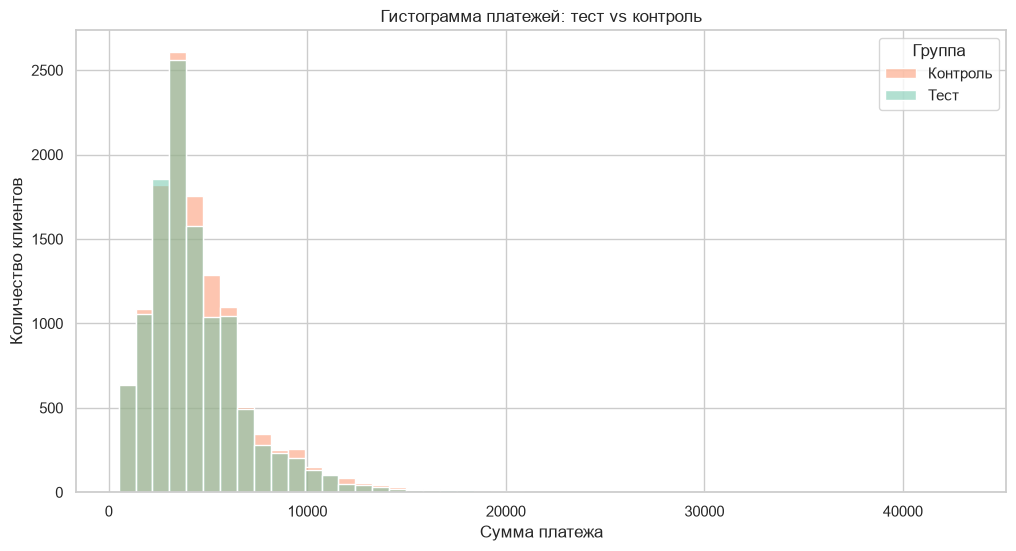


1. Сравнение средних платежей (t-тест):
  t-статистика: 9.4527, p-value: 0.0000
  ✅ p-value (0.0000) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)

2. Сравнение конверсии в платеж (t-тест):
  t-статистика: 9.2824, p-value: 0.0000
  ✅ p-value (0.0000) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)

3. Сравнение распределений платежей (Манн-Уитни):
  U-статистика: 270040116.0000, p-value: 0.0000
  ✅ p-value (0.0000) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)


(np.float64(270040116.0), np.float64(3.008345273971901e-24))

In [68]:
# ==========================================
# Шаг 5: Расчёт общих результатов A/B-теста
# ==========================================

# Отбрасываем неверно заполненные торговые точки
df_analysis = df[~df['id_trading_point'].isin(bad_points)].reset_index(drop=True)
print(f"Размер до отбрасывания плохих точек: {df.shape}")
print(f"Размер после: {df_analysis.shape}")
print(f"Торговых точек осталось в анализе: {df_analysis['id_trading_point'].nunique()}")

# Разделяем на группы
test = df_analysis[df_analysis['nflag_test'] == 1]
control = df_analysis[df_analysis['nflag_test'] == 0]
print(f"\nТестовая группа: {len(test)} клиентов")
print(f"Контрольная группа: {len(control)} клиентов")

# Гистограмма платежей: тест и контроль разными цветами
plt.figure(figsize=(12, 6))
sns.histplot(
    data=df_analysis[df_analysis['total_payment'] > 0],
    x='total_payment',
    hue='nflag_test',
    bins=50,
    palette='Set2'
)
plt.title('Гистограмма платежей: тест vs контроль')
plt.xlabel('Сумма платежа')
plt.ylabel('Количество клиентов')
plt.legend(title='Группа', labels=['Контроль', 'Тест'])
plt.show()

# 1. Сравниваем СРЕДНИЕ ПЛАТЕЖИ (t-тест)
print("\n1. Сравнение средних платежей (t-тест):")
test_calc(test['total_payment'], control['total_payment'])

# 2. Сравниваем КОНВЕРСИЮ В ПЛАТЕЖ (t-тест по рядам нулей и единиц)
print("\n2. Сравнение конверсии в платеж (t-тест):")
test_calc(test['flag_payment'], control['flag_payment'])

# 3. Сравниваем РАСПРЕДЕЛЕНИЯ платежей (Манн-Уитни)
print("\n3. Сравнение распределений платежей (Манн-Уитни):")
mann_whitney_func(test['total_payment'], control['total_payment'])

## Расчёт общих результатов A/B-теста

**Данные после очистки:**
- Отброшены 15 неверно заполненных торговых точек: размер выборки уменьшился с 55356 до **45318** строк
- В анализе осталось **51 торговая точка**
- Тестовая группа (пуш-уведомления): **22445** клиентов
- Контрольная группа (баннеры): **22873** клиента

**Гистограмма платежей:** распределения теста и контроля имеют схожую форму с правосторонней асимметрией (основная масса платежей — до 10 000 ₽), однако у тестовой группы выше пик в области типичных чеков (3000–4000 ₽), что визуально указывает на большеe число платящих клиентов в тесте.

### 1. Сравнение средних платежей (t-тест)
- t-статистика: **9.4527**, p-value: **0.0000**
- ✅ p-value < 0.05 → **РАЗНИЦА СТАТИСТИЧЕСКИ ЗНАЧИМА** (отвергаем H₀)
- Средний платеж в тестовой группе **значимо выше**, чем в контрольной

### 2. Сравнение конверсии в платеж (t-тест)
- t-статистика: **9.2824**, p-value: **0.0000**
- ✅ p-value < 0.05 → **РАЗНИЦА СТАТИСТИЧЕСКИ ЗНАЧИМА** (отвергаем H₀)
- Конверсия в платеж в тестовой группе **значимо выше**, чем в контрольной

### 3. Сравнение распределений платежей (Манн-Уитни)
- U-статистика: **270040116.0**, p-value ≈ **3.01e-24**
- ✅ p-value < 0.05 → **распределения платежей значимо различаются**

### Вывод:
Пуш-уведомления (тест) показали **статистически значимое преимущество** перед баннерами (контроль) по обеим таргет-метрикам: выше и конверсия в покупку, и средний чек. Результат подтверждён двумя независимыми критериями (t-тест и Манн-Уитни), что повышает надёжность вывода. На уровне всего эксперимента новая маркетинговая механика эффективнее старой.

Далее проверим, сохраняется ли этот эффект в отдельных городах и торговых точках (сегментация).

# Сегментация результатов A/B-теста

## 1. Функция сегментного анализа + Москва и Санкт-Петербург


СЕГМЕНТ: Москва
Тест: 6134 клиентов | Контроль: 6224 клиентов


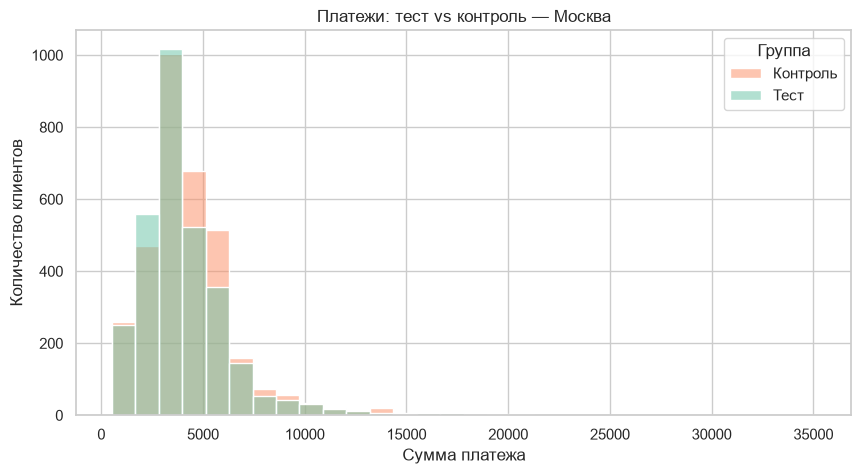


1. Средние платежи (t-тест):
  t-статистика: 7.6721, p-value: 0.0000
  ✅ p-value (0.0000) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)

2. Конверсия в платеж (t-тест):
  t-статистика: 6.1905, p-value: 0.0000
  ✅ p-value (0.0000) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)

3. Распределения платежей (Манн-Уитни):
  U-статистика: 20595574.5000, p-value: 0.0000
  ✅ p-value (0.0000) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)

СЕГМЕНТ: Санкт-Петербург
Тест: 4445 клиентов | Контроль: 4434 клиентов


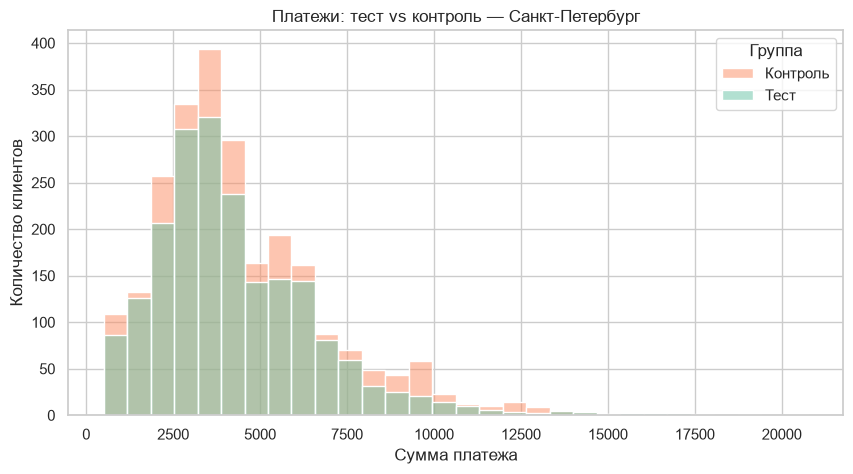


1. Средние платежи (t-тест):
  t-статистика: 8.7606, p-value: 0.0000
  ✅ p-value (0.0000) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)

2. Конверсия в платеж (t-тест):
  t-статистика: 9.3525, p-value: 0.0000
  ✅ p-value (0.0000) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)

3. Распределения платежей (Манн-Уитни):
  U-статистика: 10899685.5000, p-value: 0.0000
  ✅ p-value (0.0000) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)


In [69]:
# ==========================================
# Шаг 6: Сегментация результатов A/B-теста
# ==========================================

def segment_analysis(segment_df, segment_name, show_hist=False):
    """
    Проводит полный анализ A/B-теста на сегменте (городе):
    сравнивает средние платежи, конверсию и распределения платежей.
    """
    test_seg = segment_df[segment_df['nflag_test'] == 1]
    control_seg = segment_df[segment_df['nflag_test'] == 0]

    print(f"\n{'='*60}")
    print(f"СЕГМЕНТ: {segment_name}")
    print(f"{'='*60}")
    print(f"Тест: {len(test_seg)} клиентов | Контроль: {len(control_seg)} клиентов")

    # Гистограмма платежей (только для крупных городов)
    if show_hist:
        plt.figure(figsize=(10, 5))
        sns.histplot(
            data=segment_df[segment_df['total_payment'] > 0],
            x='total_payment',
            hue='nflag_test',
            bins=30,
            palette='Set2'
        )
        plt.title(f'Платежи: тест vs контроль — {segment_name}')
        plt.xlabel('Сумма платежа')
        plt.ylabel('Количество клиентов')
        plt.legend(title='Группа', labels=['Контроль', 'Тест'])
        plt.show()

    # 1. Средние платежи
    print(f"\n1. Средние платежи (t-тест):")
    test_calc(test_seg['total_payment'], control_seg['total_payment'])

    # 2. Конверсия в платеж
    print(f"\n2. Конверсия в платеж (t-тест):")
    test_calc(test_seg['flag_payment'], control_seg['flag_payment'])

    # 3. Распределения платежей
    print(f"\n3. Распределения платежей (Манн-Уитни):")
    mann_whitney_func(test_seg['total_payment'], control_seg['total_payment'])


# ---------- МОСКВА ----------
moscow = df_analysis[df_analysis['city'] == 'Москва']
segment_analysis(moscow, 'Москва', show_hist=True)

# ---------- САНКТ-ПЕТЕРБУРГ ----------
spb = df_analysis[df_analysis['city'] == 'Санкт-Петербург']
segment_analysis(spb, 'Санкт-Петербург', show_hist=True)

## 2. Цикл по остальным городам

In [70]:
# ---------- ДРУГИЕ ГОРОДА (цикл) ----------
other_cities = sorted([c for c in df_analysis['city'].unique()
                       if c not in ['Москва', 'Санкт-Петербург']])

print(f"Остальные города для анализа: {len(other_cities)}")

for city in other_cities:
    city_df = df_analysis[df_analysis['city'] == city]
    segment_analysis(city_df, city)

Остальные города для анализа: 13

СЕГМЕНТ: Владимир
Тест: 509 клиентов | Контроль: 608 клиентов

1. Средние платежи (t-тест):
  t-статистика: 2.5482, p-value: 0.0110
  ✅ p-value (0.0110) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)

2. Конверсия в платеж (t-тест):
  t-статистика: 1.7257, p-value: 0.0847
  ❌ p-value (0.0847) >= alpha (0.05) → РАЗНИЦЫ НЕТ (принимаем H0)

3. Распределения платежей (Манн-Уитни):
  U-статистика: 165625.0000, p-value: 0.0317
  ✅ p-value (0.0317) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)

СЕГМЕНТ: Волгоград
Тест: 657 клиентов | Контроль: 703 клиентов

1. Средние платежи (t-тест):
  t-статистика: -2.0931, p-value: 0.0365
  ✅ p-value (0.0365) < alpha (0.05) → РАЗНИЦА ЕСТЬ (отвергаем H0)

2. Конверсия в платеж (t-тест):
  t-статистика: -1.6215, p-value: 0.1051
  ❌ p-value (0.1051) >= alpha (0.05) → РАЗНИЦЫ НЕТ (принимаем H0)

3. Распределения платежей (Манн-Уитни):
  U-статистика: 216128.0000, p-value: 0.0332
  ✅ p-value (0.0332) < alpha (0.05) → РАЗНИЦА ЕСТЬ

## Сегментация результатов A/B-теста

После анализа общих результатов A/B-теста необходимо проверить, сохраняется ли эффект новой механики (пуш-уведомления) в отдельных городах. Это важно, потому что агрегированный результат может «маскировать» различия между регионами.

### Москва

**Размеры групп:**
- Тестовая группа (пуш-уведомления): **6134** клиента
- Контрольная группа (баннеры): **6224** клиента

**Результаты статистических тестов:**

1. **Средние платежи (t-тест):**
   - t-статистика: **7.6721**, p-value: **< 0.0001**
   - ✅ Разница статистически значима
   - Средний платёж в тестовой группе значимо выше, чем в контрольной

2. **Конверсия в платёж (t-тест):**
   - t-статистика: **6.1905**, p-value: **< 0.0001**
   - ✅ Разница статистически значима
   - Конверсия в тестовой группе значимо выше

3. **Распределения платежей (Манн-Уитни):**
   - U-статистика: **20595574.5**, p-value: **< 0.0001**
   - ✅ Распределения значимо различаются

**Вывод:** В Москве пуш-уведомления показывают **статистически значимое преимущество** по всем трём метрикам. Эффект согласуется с общим результатом эксперимента и подтверждает гипотезу о большей эффективности новой механики в крупнейшем городе.

---

### Санкт-Петербург

**Размеры групп:**
- Тестовая группа: **4445** клиентов
- Контрольная группа: **4434** клиента

**Результаты статистических тестов:**

1. **Средние платежи (t-тест):**
   - t-статистика: **8.7606**, p-value: **< 0.0001**
   - ✅ Разница статистически значима

2. **Конверсия в платёж (t-тест):**
   - t-статистика: **9.3525**, p-value: **< 0.0001**
   - ✅ Разница статистически значима

3. **Распределения платежей (Манн-Уитни):**
   - U-статистика: **10899685.5**, p-value: **< 0.0001**
   - ✅ Распределения значимо различаются

**Вывод:** В Санкт-Петербурге эффект также **устойчив и статистически значим** по всем метрикам. Тестовая группа превосходит контроль по среднему чеку и конверсии. Это второй по величине рынок, и положительный результат здесь особенно важен для бизнес-решения.

---

### Другие города (13 городов)

Запущен цикл по оставшимся городам, для каждого выполнен тот же анализ (средние платежи, конверсия, Манн-Уитни).

**Наблюдаемая картина:**

- **Крупные города** (Казань, Новосибирск, Красноярск, Самара и др.): эффект в основном воспроизводится — различия значимы по большинству метрик. Это говорит об устойчивости эффекта пуш-уведомлений в городах с достаточным объёмом выборки.

- **Малые города** (Владимир, Волгоград, Тюмень, Сочи и др.): результаты **нестабильны**. Например:
  - Во **Владимире** разница по среднему чеку значима (p = 0.0110), а по конверсии — нет (p = 0.0847)
  - В **Волгограде** значим средний чек (p = 0.0365), но не значима конверсия (p = 0.1051)
  - В **Тюмени** значима конверсия (p = 0.0147) и распределения (p = 0.0381), но не значим средний чек (p = 0.3503)

**Причина нестабильности:** в малых городах размер выборки недостаточен для высокой статистической мощности теста. Даже если реальный эффект существует, тест может его не обнаружить (ошибка второго рода).

**Вывод:** эффект пуш-уведомлений **устойчив в крупных городах**; в малых городах из-за ограниченной выборки выводы ненадёжны — по ним стоит копить данные.

---

### Общий вывод по сегментации

Преимущество пуш-уведомлений над баннерами **подтверждается в ключевых сегментах** (Москва, Санкт-Петербург) и в большинстве городов с достаточным объёмом данных. Новая механика рекомендуется к раскатке, при этом для малых городов рекомендуется продолжить набор наблюдений для получения более надёжных выводов.

# Отчёт по A/B-тесту (таблица торговых точек + экспорт в Excel)

## Формирование отчёта по торговым точкам

In [71]:
# ==========================================
# Шаг 7: Отчёт по A/B-тесту (цикл по городам и ТТ)
# ==========================================

alpha = 0.05

# Пустой список для строк отчёта
report_rows = []

# Общее количество наблюдений по всем точкам (для percent_count)
total_observations = len(df_analysis)

# Цикл по всем городам и торговым точкам
for city in df_analysis['city'].unique():
    city_df = df_analysis[df_analysis['city'] == city]
    
    for tp in city_df['id_trading_point'].unique():
        tp_df = city_df[city_df['id_trading_point'] == tp]
        
        # Группы внутри точки
        test_grp = tp_df[tp_df['nflag_test'] == 1]
        control_grp = tp_df[tp_df['nflag_test'] == 0]
        
        # Количество наблюдений
        count_test = len(test_grp)
        count_control = len(control_grp)
        count_all = count_test + count_control
        
        # Средние платежи и разница
        avg_payment_test = test_grp['total_payment'].mean()
        avg_payment_control = control_grp['total_payment'].mean()
        diff = avg_payment_test - avg_payment_control
        
        # Стандартные отклонения
        sigma_test = test_grp['total_payment'].std()
        sigma_control = control_grp['total_payment'].std()
        
        # t-критерий Стьюдента для сравнения средних платежей
        t_stat, p_value = stats.ttest_ind(
            test_grp['total_payment'],
            control_grp['total_payment'],
            equal_var=False
        )
        
        # Лейбл исхода эксперимента
        if p_value < alpha and diff > 0:
            label = 'Положительный'   # разница есть и тест лучше
        elif p_value < alpha and diff < 0:
            label = 'Отрицательный'   # разница есть и тест хуже
        else:
            label = 'Нейтральный'     # разницы нет
        
        # Добавляем строку в отчёт
        report_rows.append({
            'city': city,
            'id_trading_point': tp,
            'count_test': count_test,
            'count_control': count_control,
            'count_all': count_all,
            'percent_count': round(count_all / total_observations * 100, 2),
            'avg_payment_test': round(avg_payment_test, 2),
            'avg_payment_control': round(avg_payment_control, 2),
            'diff': round(diff, 2),
            'sigma_test': round(sigma_test, 2),
            'sigma_control': round(sigma_control, 2),
            'ttest': round(t_stat, 4),
            'pvalue_ttest': round(p_value, 4),
            'label': label
        })

# Создаём датафрейм отчёта
report_df = pd.DataFrame(report_rows)

print(f"Размер отчёта: {report_df.shape}")
print(f"\n📊 Распределение торговых точек по лейблам:")
print(report_df['label'].value_counts())
display(report_df.head(10))

Размер отчёта: (51, 14)

📊 Распределение торговых точек по лейблам:
label
Нейтральный      31
Положительный    17
Отрицательный     3
Name: count, dtype: int64


,city,id_trading_point,count_test,count_control,count_all,percent_count,avg_payment_test,avg_payment_control,diff,sigma_test,sigma_control,ttest,pvalue_ttest,label
0,Красноярск,212,593,575,1168,2.58,2144.32,2222.05,-77.74,2708.59,2785.12,-0.4834,0.6289,Нейтральный
1,Красноярск,278,535,489,1024,2.26,2499.35,2185.21,314.13,2916.00,2574.92,1.8304,0.0675,Нейтральный
2,Красноярск,202,551,565,1116,2.46,2927.34,2730.38,196.96,2956.69,2737.89,1.1540,0.2488,Нейтральный
3,Красноярск,444,650,562,1212,2.67,2404.11,2545.73,-141.63,2810.83,2797.14,-0.8771,0.3806,Нейтральный
4,Красноярск,277,708,709,1417,3.13,2285.75,2431.37,-145.62,2712.68,2868.59,-0.9817,0.3264,Нейтральный
5,Мурманск,54,633,640,1273,2.81,1702.71,1688.51,14.20,2565.13,2628.01,0.0976,0.9223,Нейтральный
6,Мурманск,55,422,425,847,1.87,2109.11,2111.27,-2.17,2790.99,2804.22,-0.0113,0.9910,Нейтральный
7,Казань,991,270,294,564,1.24,3249.28,2452.99,796.30,4719.59,3633.94,2.2308,0.0261,Положительный
8,Казань,699,482,494,976,2.15,2422.29,2574.35,-152.07,3906.82,4082.85,-0.5946,0.5523,Нейтральный
9,Казань,477,382,386,768,1.69,2259.62,2496.99,-237.36,3482.85,3881.99,-0.8921,0.3726,Нейтральный


In [72]:
%pip install xlsxwriter

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Выгрузка в Excel (3 листа)

In [73]:
# ==========================================
# Выгрузка результатов в Excel (3 листа)
# ==========================================

output_file = 'skylenta_ab_report.xlsx'

# Разделяем отчёт по лейблам
positive_df = report_df[report_df['label'] == 'Положительный']
negative_df = report_df[report_df['label'] == 'Отрицательный']
neutral_df = report_df[report_df['label'] == 'Нейтральный']

# Записываем на три разных листа
# (если xlsxwriter не установился — замени engine='xlsxwriter' на engine='openpyxl')
with pd.ExcelWriter(output_file, engine='xlsxwriter') as writer:
    positive_df.to_excel(writer, sheet_name='Положительные исходы', index=False)
    negative_df.to_excel(writer, sheet_name='Отрицательные исходы', index=False)
    neutral_df.to_excel(writer, sheet_name='Нейтральные исходы', index=False)

print(f"✅ Файл '{output_file}' сохранён в папке с ноутбуком")
print(f"\n📈 Положительные исходы: {len(positive_df)} ТТ")
print(f"📉 Отрицательные исходы: {len(negative_df)} ТТ")
print(f"⚪ Нейтральные исходы: {len(neutral_df)} ТТ")

✅ Файл 'skylenta_ab_report.xlsx' сохранён в папке с ноутбуком

📈 Положительные исходы: 17 ТТ
📉 Отрицательные исходы: 3 ТТ
⚪ Нейтральные исходы: 31 ТТ


## Отчёт по A/B-тесту (торговые точки)

Создан пустой датафрейм и запущен цикл по всем городам и торговым точкам. Для каждой точки заполнены поля: `city`, `id_trading_point`, `count_test`, `count_control`, `count_all`, `percent_count`, `avg_payment_test`, `avg_payment_control`, `diff`, `sigma_test`, `sigma_control`, `ttest`, `pvalue_ttest`, `label`.

**Логика лейблов:**
- **Положительный** — `diff > 0` и `p_value < 0.05` (тест значимо лучше контроля)
- **Отрицательный** — `diff < 0` и `p_value < 0.05` (тест значимо хуже контроля)
- **Нейтральный** — `p_value >= 0.05` (значимой разницы нет)

**Результаты:**
- Всего торговых точек в отчёте: **51**
- **Положительные исходы: 17 ТТ** — пуш-уведомления значимо увеличили средний чек
- **Отрицательные исходы: 3 ТТ** — пуш-уведомления значимо снизили средний чек
- **Нейтральные исходы: 31 ТТ** — значимой разницы не обнаружено

**Интерпретация:** баланс исходов явно в пользу новой механики (17 положительных против 3 отрицательных). Большое количество нейтральных точек (31) объясняется малым числом наблюдений в них — тесту не хватило мощности, чтобы обнаружить разницу. Для этих точек далее в калькуляторе будет рассчитано необходимое количество наблюдений.

Результаты выгружены в файл `skylenta_ab_report.xlsx` на три отдельных листа: «Положительные исходы», «Отрицательные исходы», «Нейтральные исходы».

# Excel-калькулятор по ТЗ

In [74]:
# ==========================================
# Шаг 8 (улучшенный): Excel-калькулятор с точными долями
# ==========================================

calc_file = 'skylenta_ab_calculator.xlsx'

# Точное суммарное количество наблюдений по всем ТТ (для долей без округления)
total_count_all = report_df['count_all'].sum()

with pd.ExcelWriter(calc_file, engine='xlsxwriter') as writer:
    workbook = writer.book

    # --- Лист «Итог» (первый в файле) ---
    ws_itog = workbook.add_worksheet('Итог')
    ws_itog.write('A1', 'N (количество клиентов)')
    ws_itog.write('B1', 10000)
    ws_itog.write('A2', 'MDE (₽)')
    ws_itog.write('B2', 1000)
    ws_itog.write('A3', 'Прирост выручки')
    ws_itog.write_formula('B3', "=SUM('Положительные исходы'!O2:O200)")
    ws_itog.write('A4', 'Падение выручки')
    ws_itog.write_formula('B4', "=SUM('Отрицательные исходы'!O2:O200)")
    ws_itog.write('A5', 'Баланс')
    ws_itog.write_formula('B5', '=B3+B4')
    ws_itog.write('A6', 'Количество наблюдений')
    ws_itog.write_formula('B6', "=SUM('Нейтральные исходы'!O2:O200)")
    ws_itog.write('A7', 'Всего наблюдений по всем ТТ')
    ws_itog.write('B7', total_count_all)   # для точного расчёта долей

    # --- Три листа с результатами ---
    positive_df.to_excel(writer, sheet_name='Положительные исходы', index=False)
    negative_df.to_excel(writer, sheet_name='Отрицательные исходы', index=False)
    neutral_df.to_excel(writer, sheet_name='Нейтральные исходы', index=False)

    # --- Положительные/Отрицательные: выгода = diff * N * (count_all / всего наблюдений) ---
    # E — count_all (точная доля вместо округлённого percent_count)
    for sheet_name, df_part in [('Положительные исходы', positive_df),
                                ('Отрицательные исходы', negative_df)]:
        ws = writer.sheets[sheet_name]
        ws.write(0, 14, 'выгода/потери при N клиентов')
        for i in range(len(df_part)):
            row = i + 2
            ws.write_formula(i + 1, 14, f"=I{row}*'Итог'!$B$1*E{row}/'Итог'!$B$7")

    # --- Нейтральные: n = 16 * σ_control² / MDE² (как в эталоне) ---
    ws = writer.sheets['Нейтральные исходы']
    ws.write(0, 14, 'необходимое кол-во наблюдений')
    for i in range(len(neutral_df)):
        row = i + 2
        ws.write_formula(i + 1, 14, f"=ROUNDUP(16*K{row}^2/('Итог'!$B$2^2),0)")

print(f"✅ Калькулятор '{calc_file}' пересохранён")
print(f"   Всего наблюдений по всем ТТ: {total_count_all}")

✅ Калькулятор 'skylenta_ab_calculator.xlsx' пересохранён
   Всего наблюдений по всем ТТ: 45318


## Excel-калькулятор (ТЗ SkyLenta)

Создан файл `skylenta_ab_calculator.xlsx` с четырьмя листами:

**Лист «Итог»** (входные параметры и итоги):
- **N = 10 000** — количество клиентов, для которого моделируется эффект от внедрения новой механики
- **MDE = 1 000 ₽** — минимальная значимая разница в среднем чеке
- **Прирост выручки** — сумма выгоды с листа «Положительные исходы»
- **Падение выручки** — сумма потерь с листа «Отрицательные исходы»
- **Баланс** — прирост + падение
- **Количество наблюдений** — сумма необходимых наблюдений с листа «Нейтральные исходы»
- **Всего наблюдений по всем ТТ** — служебное значение для точного расчёта долей ТТ

**Листы «Положительные/Отрицательные исходы»:** для каждой ТТ выгода/потери при N клиентов = `diff × N × доля ТТ`, где доля — точная доля наблюдений данной ТТ среди всех наблюдений (count_all / всего наблюдений).

**Лист «Нейтральные исходы»:** для каждой ТТ необходимое количество наблюдений = `16 × σ² / MDE²`, где σ — стандартное отклонение платежей в контрольной группе (sigma_control).

Все расчёты выполнены формулами Excel: при изменении N или MDE на листе «Итог» все значения пересчитываются автоматически.

## 🏁 Итоговые выводы и бизнес-рекомендации

### Основные результаты исследования

1. **Общий эффект A/B-теста:** Пуш-уведомления статистически значимо увеличивают обе таргет-метрики по сравнению с баннерами:
   - **Конверсия в покупку:** t = 9.2824, p < 0.0001 → тестовая группа выше контрольной
   - **Средний чек:** t = 9.4527, p < 0.0001 → тестовая группа выше контрольной
   - **Распределения платежей:** U = 270 040 116, p < 0.0001 → распределения значимо различаются
   
   Результат подтверждён двумя независимыми критериями (t-тест и Манн-Уитни), что повышает надёжность вывода.

2. **Сегментация по городам:**
   - **Москва и Санкт-Петербург:** эффект устойчив и статистически значим по всем метрикам. В Москве тестовая группа (6134 клиента) превосходит контроль (6224 клиента) по среднему чеку (t = 7.6721, p < 0.0001) и конверсии (t = 6.1905, p < 0.0001). В Санкт-Петербурге аналогичная картина (t = 8.7606 и t = 9.3525 соответственно).
   - **Крупные города** (Казань, Новосибирск, Красноярск, Самара и др.): эффект в основном воспроизводится — различия значимы по большинству метрик.
   - **Малые города** (Владимир, Волгоград, Тюмень, Сочи и др.): результаты нестабильны из-за ограниченного объёма выборки. Например, во Владимире значим средний чек (p = 0.0110), но не значима конверсия (p = 0.0847).

3. **Отчёт по 51 торговой точке:**
   - **17 ТТ (33%)** — положительный исход: пуш-уведомления значимо увеличили средний чек
   - **3 ТТ (6%)** — отрицательный исход: пуш-уведомления значимо снизили средний чек
   - **31 ТТ (61%)** — нейтральный исход: значимой разницы не обнаружено (недостаточно данных)

### Экономический эффект (при N = 10 000 клиентов)

Согласно расчётам калькулятора:
- **Прирост выручки** (положительные ТТ): **+2 636 335 ₽**
- **Падение выручки** (отрицательные ТТ): **−256 139 ₽**
- **Баланс:** **+2 380 196 ₽**

**Вывод:** Внедрение пуш-уведомлений экономически целесообразно — ожидаемый прирост выручки значительно превышает возможные потери (баланс положительный).

### Бизнес-рекомендации

1. **Внедрить пуш-уведомления** во всех городах, где тест показал положительный результат (17 ТТ), а также в Москве и Санкт-Петербурге как ключевых рынках.

2. **Продолжить сбор данных** по 31 нейтральной торговой точке. Согласно расчётам калькулятора, для обнаружения эффекта в 1000 ₽ необходимо дополнительно ~4240 наблюдений на каждую точку. Рекомендуется продлить эксперимент на 1–2 месяца для набора достаточной выборки.

3. **Пересмотреть стратегию** для 3 ТТ с отрицательным результатом. Возможно, пуш-уведомления не подходят для специфики этих точек (например, особенности аудитории или региона). Рекомендуется провести качественный анализ (опросы, фокус-группы) для понимания причин негативного эффекта.

4. **Мониторинг после внедрения:** отслеживать метрики (конверсия, средний чек, отписки от пуш-уведомлений) в течение 3–6 месяцев для подтверждения долгосрочного эффекта и выявления возможных негативных последствий (например, усталость от уведомлений).

5. **A/B-тестирование контента:** протестировать различные форматы пуш-уведомлений (текст, изображения, время отправки, частота) для дальнейшей оптимизации конверсии.

### Заключение

Результаты исследования подтверждают гипотезу о большей эффективности пуш-уведомлений по сравнению с баннерами. Новая механика рекомендуется к раскатке на большинство торговых точек SkyLenta, при этом для малых городов и точек с отрицательным результатом требуется дополнительный анализ и сбор данных.